Assignment 9 - Perform Imag Classification using pretarined Vision Transformer and compare its performance with CNN model

In [ ]:
!pip -q install datasets

In [ ]:
import torch
import torchvision
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torchvision.models import (
    resnet18, ResNet18_Weights,
    vit_b_16, ViT_B_16_Weights
)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix,
    ConfusionMatrixDisplay
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

dataset = OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    transform=transform,
    download=True
)

print("Total images:", len(dataset))
print("Number of classes:", len(dataset.classes))

Device: cpu


100%|██████████| 792M/792M [00:34<00:00, 22.8MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 15.3MB/s]


Total images: 3680
Number of classes: 37


In [ ]:
targets = np.array(dataset._labels)
indices = np.arange(len(dataset))

train_idx, test_idx = train_test_split(
    indices,
    train_size=400,
    test_size=160,
    stratify=targets,
    random_state=42
)

train_data = Subset(dataset, train_idx)
test_data = Subset(dataset, test_idx)

train_loader = DataLoader(
    train_data, batch_size=16, shuffle=True, num_workers=2
)
test_loader = DataLoader(
    test_data, batch_size=16, shuffle=False, num_workers=2
)

print("Training images:", len(train_data))
print("Testing images:", len(test_data))

Training images: 400
Testing images: 160


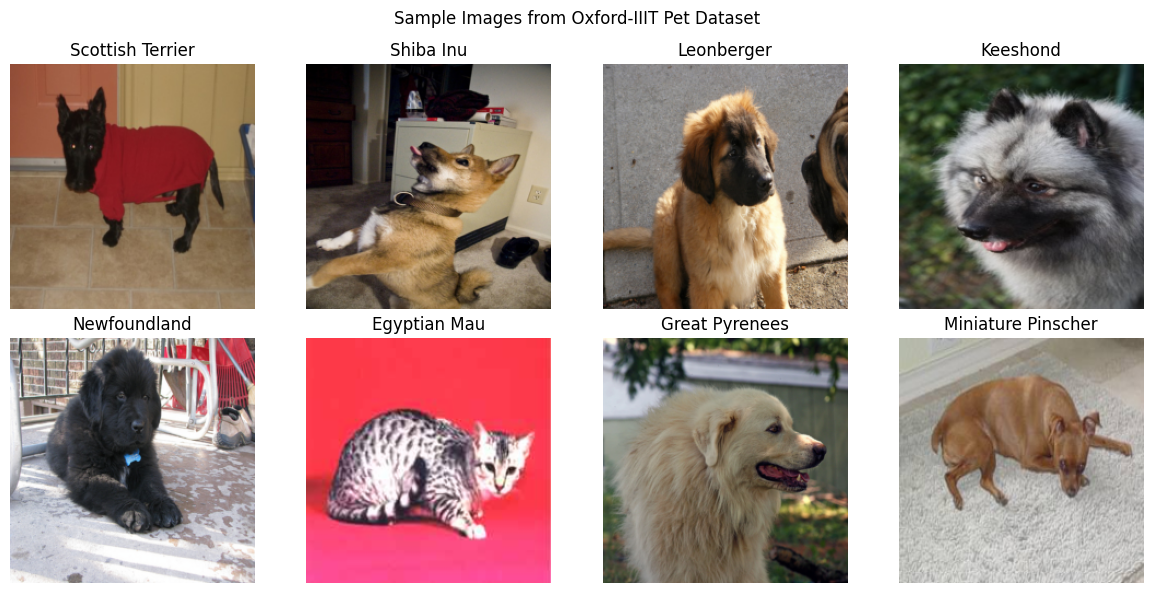

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    image = image.permute(1, 2, 0).numpy()
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(dataset.classes[label])
    ax.axis("off")

plt.suptitle("Sample Images from Oxford-IIIT Pet Dataset")
plt.tight_layout()
plt.show()

In [ ]:
# Pretrained CNN
cnn = resnet18(weights=ResNet18_Weights.DEFAULT)

for param in cnn.parameters():
    param.requires_grad = False

cnn.fc = nn.Linear(cnn.fc.in_features, len(dataset.classes))
cnn = cnn.to(device)

# Pretrained Vision Transformer
vit = vit_b_16(weights=ViT_B_16_Weights.DEFAULT)

for param in vit.parameters():
    param.requires_grad = False

vit.heads.head = nn.Linear(
    vit.heads.head.in_features, len(dataset.classes)
)
vit = vit.to(device)

print("Pretrained ResNet18 and ViT loaded.")

Pretrained ResNet18 and ViT loaded.


In [ ]:
def train_evaluate(model, name, epochs=2):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=0.001
    )

    train_losses = []
    val_losses = []
    start_time = time.time()

    for epoch in range(epochs):
        model.train()
        running_loss = 0.0

        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        train_losses.append(running_loss / len(train_loader))

        model.eval()
        validation_loss = 0.0

        with torch.no_grad():
            for images, labels in test_loader:
                images, labels = images.to(device), labels.to(device)
                validation_loss += criterion(model(images), labels).item()

        val_losses.append(validation_loss / len(test_loader))

        print(
            f"{name} | Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_losses[-1]:.4f} | "
            f"Test Loss: {val_losses[-1]:.4f}"
        )

    training_time = time.time() - start_time

    model.eval()
    actual, predicted = [], []

    with torch.no_grad():
        for images, labels in test_loader:
            outputs = model(images.to(device))
            predicted.extend(outputs.argmax(1).cpu().numpy())
            actual.extend(labels.numpy())

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            actual, predicted, average="macro", zero_division=0
        ),
        "Training Time (s)": round(training_time, 2)
    }

    return metrics, train_losses, val_losses, actual, predicted

cnn_results, cnn_train_loss, cnn_val_loss, cnn_y, cnn_pred = train_evaluate(
    cnn, "ResNet18 CNN"
)

vit_results, vit_train_loss, vit_val_loss, vit_y, vit_pred = train_evaluate(
    vit, "Vision Transformer"
)

results_df = pd.DataFrame([cnn_results, vit_results])
print("\nPerformance Comparison:")
print(results_df.round(4).to_string(index=False))

ResNet18 CNN | Epoch 1/2 | Train Loss: 3.5371 | Test Loss: 2.8441
ResNet18 CNN | Epoch 2/2 | Train Loss: 2.3867 | Test Loss: 2.0931
Vision Transformer | Epoch 1/2 | Train Loss: 2.7098 | Test Loss: 1.7022
Vision Transformer | Epoch 2/2 | Train Loss: 0.9476 | Test Loss: 0.9026

Performance Comparison:
             Model  Accuracy  Precision  Recall  F1-Score  Training Time (s)
      ResNet18 CNN    0.6312     0.7454  0.6297    0.6143             122.11
Vision Transformer    0.8312     0.8780  0.8405    0.8339             801.32


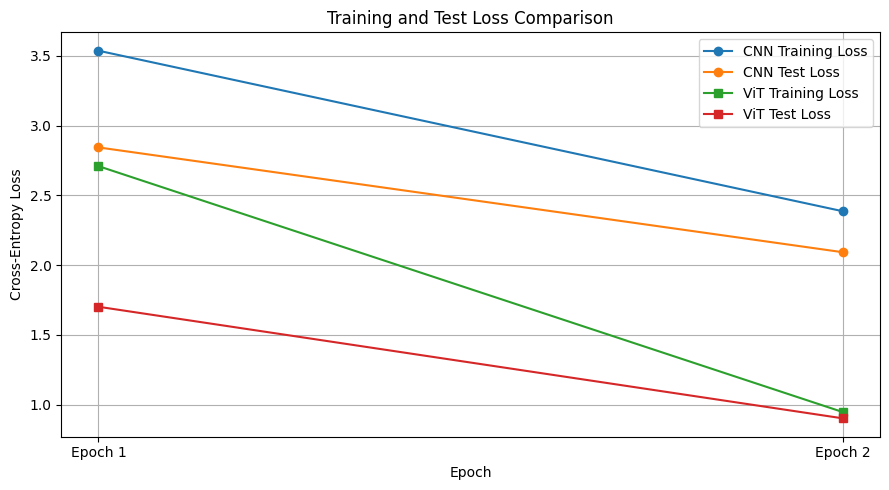

In [ ]:
plt.figure(figsize=(9, 5))

plt.plot(cnn_train_loss, marker="o", label="CNN Training Loss")
plt.plot(cnn_val_loss, marker="o", label="CNN Test Loss")
plt.plot(vit_train_loss, marker="s", label="ViT Training Loss")
plt.plot(vit_val_loss, marker="s", label="ViT Test Loss")

plt.title("Training and Test Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(2), ["Epoch 1", "Epoch 2"])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

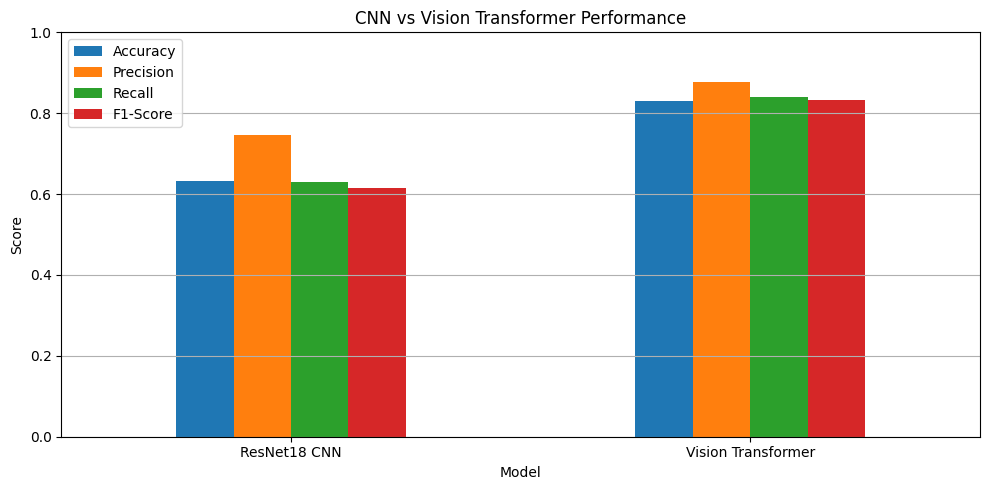

In [ ]:
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
].plot(kind="bar", figsize=(10, 5))

plt.title("CNN vs Vision Transformer Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

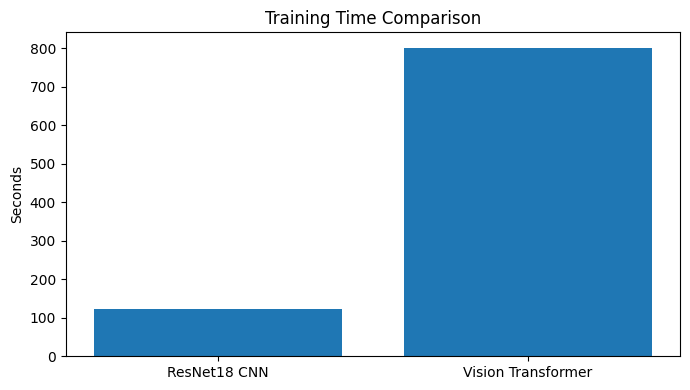

In [ ]:
plt.figure(figsize=(7, 4))
plt.bar(results_df["Model"], results_df["Training Time (s)"])
plt.title("Training Time Comparison")
plt.ylabel("Seconds")
plt.tight_layout()
plt.show()

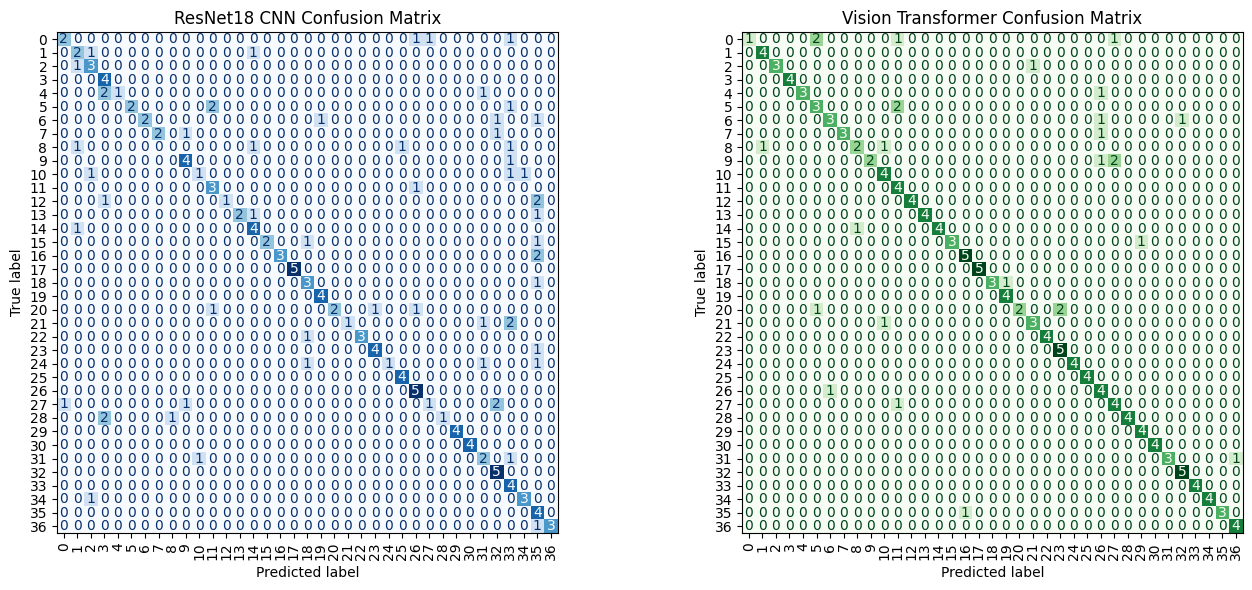

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ConfusionMatrixDisplay.from_predictions(
    cnn_y, cnn_pred, ax=axes[0], cmap="Blues",
    xticks_rotation="vertical", colorbar=False
)
axes[0].set_title("ResNet18 CNN Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    vit_y, vit_pred, ax=axes[1], cmap="Greens",
    xticks_rotation="vertical", colorbar=False
)
axes[1].set_title("Vision Transformer Confusion Matrix")

plt.tight_layout()
plt.show()

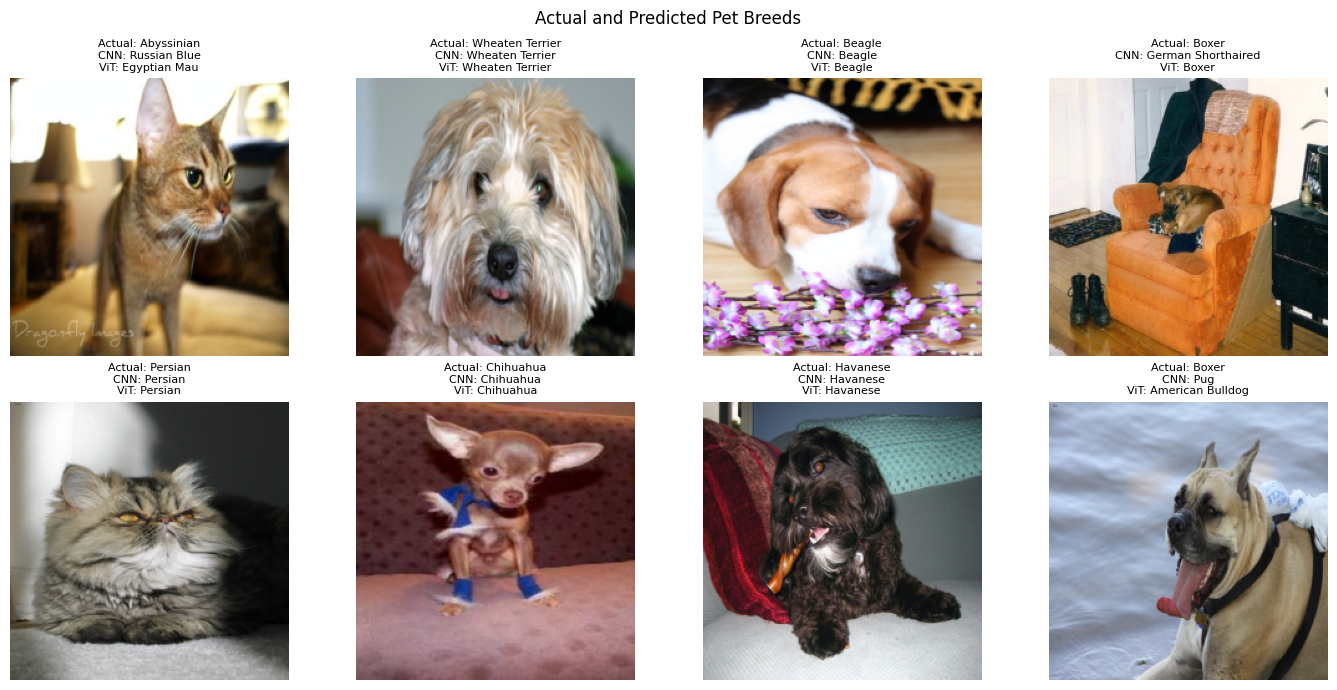

In [ ]:
classes = dataset.classes
images, labels = next(iter(test_loader))

cnn.eval()
vit.eval()

with torch.no_grad():
    cnn_pred_batch = cnn(images.to(device)).argmax(1).cpu().numpy()
    vit_pred_batch = vit(images.to(device)).argmax(1).cpu().numpy()

fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for i, ax in enumerate(axes.flat):
    image = images[i].permute(1, 2, 0).numpy()
    image = image * np.array([0.229, 0.224, 0.225])
    image = image + np.array([0.485, 0.456, 0.406])
    image = np.clip(image, 0, 1)

    ax.imshow(image)
    ax.set_title(
        f"Actual: {classes[labels[i]]}\n"
        f"CNN: {classes[cnn_pred_batch[i]]}\n"
        f"ViT: {classes[vit_pred_batch[i]]}",
        fontsize=8
    )
    ax.axis("off")

plt.suptitle("Actual and Predicted Pet Breeds")
plt.tight_layout()
plt.show()